# Saharan dust reaches Greece with CAMS 🏜️
### Copernicus Atmosphere Monitoring Service · free account

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/greece/dust_cams.ipynb)

From 11 to 15 November 2026 strong southerly winds carried dust from Libya across the Ionian Sea to Greece. This
notebook maps **Friday 13 November at 12:00 UTC**, when the dust peaked over the Peloponnese and Athens, from the
**CAMS global forecast** run by ECMWF for the European Union. The animation on the slide uses the CAMS European
air-quality forecast (about 10 km); the global forecast here (about 40 km) is kept for longer and shows the whole plume
from the Sahara.

*In Google Colab? Press **Runtime → Run all**. The data store queues requests, so step 2 can take a few minutes.*

In [ ]:
# Install the open-source tools (Colab / fresh machine). Takes ~1 minute.
!pip install -q "earthkit-data[cds]" earthkit-plots

## Your free Copernicus key

Copernicus data is free and open, but the data stores ask you to register once so they can manage the queue:
1. Create an account at [cds.climate.copernicus.eu](https://cds.climate.copernicus.eu) (the same login works for the
   Atmosphere Data Store).
2. Open the [dataset page](https://ads.atmosphere.copernicus.eu/datasets/cams-global-atmospheric-composition-forecasts?tab=download) on the Atmosphere Data Store and accept its licence (bottom of the Download tab). You only do this once.
3. Copy your API key from your [profile page](https://cds.climate.copernicus.eu/profile) and paste it below.

**Use your own key.** Everyone who runs this notebook needs their own free Copernicus account and key. The next cell asks
for it in a hidden box and saves it on the machine running the notebook (in Colab that is a temporary machine, wiped when
you close the tab). The key is never stored in the notebook, so don't paste it into a code cell, and don't share a notebook
or screenshot that shows it. On your own computer with `~/.cdsapirc` / `~/.adsapirc` already in place, the cell asks nothing.

In [2]:
import os
from getpass import getpass
rc = {"~/.cdsapirc": "https://cds.climate.copernicus.eu/api", "~/.adsapirc": "https://ads.atmosphere.copernicus.eu/api"}
missing = [p for p in rc if not os.path.exists(os.path.expanduser(p))]
if missing:
    key = getpass("Copernicus API key: ")
    for p in missing:
        with open(os.path.expanduser(p), "w") as f:
            f.write(f"url: {rc[p]}\nkey: {key}\n")
print("Copernicus key ready")

Copernicus key ready


In [3]:
import pyproj                     # import before earthkit.data (avoids a crash at exit)
import datetime as dt
import earthkit.data as ekd
import earthkit.plots as ekp
import cartopy.crs as ccrs
import matplotlib.patheffects as pe
import numpy as np

## 1 · Choose the day and the area

In [4]:
AREA = [43.0, 8.0, 26.0, 32.0]             # north, west, south, east: from the Libyan desert to the Balkans
DATE = "2026-11-13"
LEAD = 12                                  # hours after 00 UTC
CITIES = [("Athens", 37.984, 23.728), ("Thessaloniki", 40.640, 22.944), ("Patras", 38.246, 21.735),
          ("Heraklion", 35.339, 25.144), ("Rhodes", 36.434, 28.217)]

def label_cities(chart):
    for name, la, lo in CITIES:
        chart.scatter(x=[lo], y=[la], s=36, color="#ffd23f", edgecolors="#1a1a1a", linewidths=0.8, zorder=10)
        chart.ax.text(lo, la, f"  {name}", transform=ccrs.PlateCarree(), fontsize=10, fontweight="bold", zorder=11,
                      color="#1d2230", path_effects=[pe.withStroke(linewidth=2.5, foreground="white")])

## 2 · Get the dust forecast

In [5]:
cams = ekd.from_source("ads", "cams-global-atmospheric-composition-forecasts", {
    "variable": "dust_aerosol_optical_depth_550nm", "date": f"{DATE}/{DATE}", "time": "00:00",
    "type": "forecast", "leadtime_hour": str(LEAD), "area": AREA, "data_format": "grib"}).to_xarray()
duaod = cams[list(cams.data_vars)[0]].squeeze()
print(f"Dust optical depth up to {float(duaod.max()):.2f}")

Dust optical depth up to 0.46


## 3 · Map it

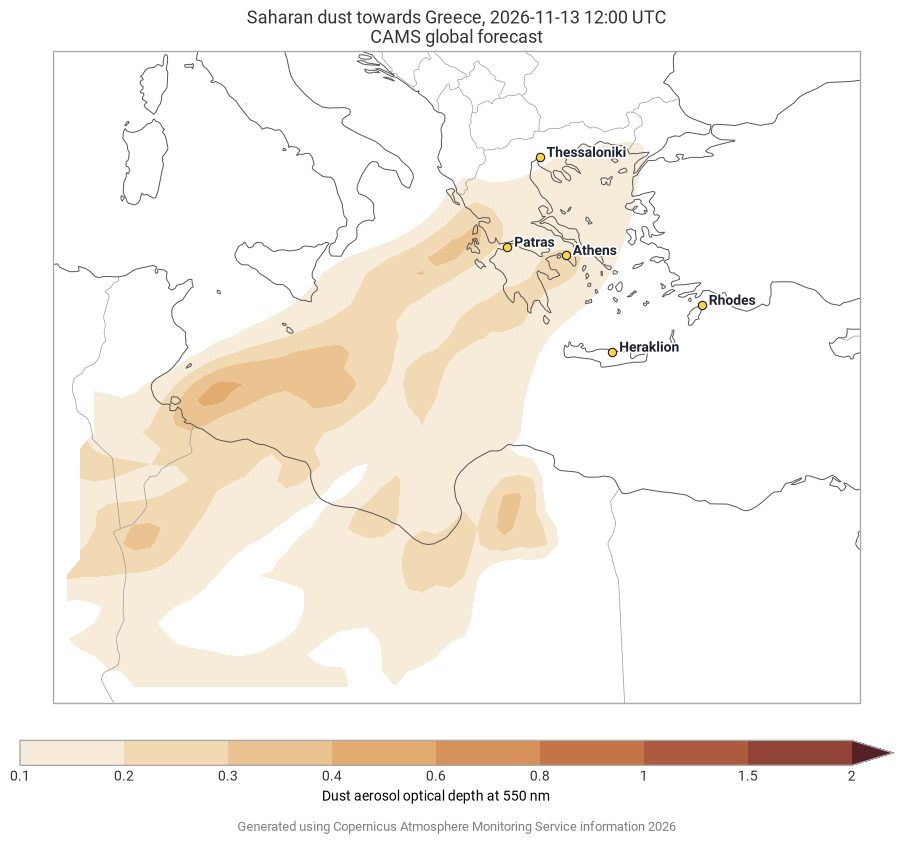

In [6]:
colors = ["#f6ecd9", "#efd3a8", "#e6b77d", "#d9955a", "#c27046", "#a34f3c", "#7d3533", "#562126"]
style = ekp.styles.Style(levels=[0.1, 0.2, 0.3, 0.4, 0.6, 0.8, 1.0, 1.5, 2.0], colors=colors, extend="max")
chart = ekp.Map(domain=[AREA[1], AREA[3], AREA[2], AREA[0]], figsize=(11, 8))
chart.contourf(duaod, style=style)
chart.coastlines(linewidth=0.7); chart.borders(linewidth=0.5)
label_cities(chart)
chart.legend(label="Dust aerosol optical depth at 550 nm")
chart.title(f"Saharan dust towards Greece, {DATE} {LEAD:02d}:00 UTC\nCAMS global forecast", fontsize=13)
chart.attribution("Generated using Copernicus Atmosphere Monitoring Service information 2026")
chart.save("dust_cams.png")
chart.show()

## 4 · Your turn 🌍

- **The days before and after:** `DATE = "2026-11-11"` to `"2026-11-15"`.
- **Today and the next five days:** set `DATE` to yesterday and `LEAD` from 0 to 120.
- **Dust near the ground at 10 km:** the CAMS European air-quality forecast (`cams-europe-air-quality-forecasts`,
  variable `"dust"`, `model` `"ensemble"`, `level` `"0"`) for recent dates.

### Data & licence
Copernicus data is free and open under the Copernicus licence (CC-BY 4.0). Credit:
*Generated using Copernicus Atmosphere Monitoring Service information 2026.* ECMWF runs the Copernicus Atmosphere Monitoring Service and the
Copernicus Climate Change Service for the European Union.

[Climate Data Store](https://cds.climate.copernicus.eu) · [Atmosphere Data Store](https://ads.atmosphere.copernicus.eu) ·
[earthkit](https://earthkit.ecmwf.int)